# A bacterium in the computer

## What is metabolism?

Every cell is a tiny chemical factory. It takes in food (for example sugar) and, step by step, turns it into energy and into the building blocks of a new cell. Each step is a **chemical reaction**, and each reaction is carried out by an **enzyme**. The instructions for building each enzyme are in a **gene**.

```mermaid
flowchart LR
    A[Food<br>glucose, oxygen, ...] --> B[Reactions<br>made possible by enzymes]
    B --> C[Building blocks<br>amino acids, DNA, fats, ...]
    C --> D[New cell]
    B --> E[Waste<br>CO2, water, ...]
```

Scientists have collected all known reactions of *E. coli* into a **metabolic model**. Today we use a small version of it, the *E. coli* **core model** from the [BiGG database](http://bigg.ucsd.edu/models/e_coli_core).

First run the cell below; it sets the language of the messages. Then load the model.

In [1]:
setLanguage('en')   % language of the messages below

Language: English


In [2]:
model = loadEcoli();

Model loaded: E. coli core model with 95 reactions, 72 metabolites and 137 genes.


## A look inside the model

Each reaction has a short ID and a full name. Here are the first ten:

In [3]:
[model.rxns(1:10), model.rxnNames(1:10)]

ans =
{
  [1,1] = PFK
  [2,1] = PFL
  [3,1] = PGI
  [4,1] = PGK
  [5,1] = PGL
  [6,1] = ACALD
  [7,1] = AKGt2r
  [8,1] = PGM
  [9,1] = PIt2r
  [10,1] = ALCD2x
  [1,2] = Phosphofructokinase
  [2,2] = Pyruvate formate lyase
  [3,2] = Glucose-6-phosphate isomerase
  [4,2] = Phosphoglycerate kinase
  [5,2] = 6-phosphogluconolactonase
  [6,2] = Acetaldehyde dehydrogenase (acetylating)
  [7,2] = 2 oxoglutarate reversible transport via symport
  [8,2] = Phosphoglycerate mutase
  [9,2] = Phosphate reversible transport via symport
  [10,2] = Alcohol dehydrogenase (ethanol)
}



Let's look at one reaction more closely: **PGK** (phosphoglycerate kinase). It is one of the steps that break down sugar and produce energy in the form of **ATP**, the cell's "battery".

The output shows the reaction formula and, at the end, the **gene** that codes for its enzyme.

In [4]:
printRxnFormula(model, 'rxnAbbrList', 'PGK', 'gprFlag', true);

PGK	3pg_c + atp_c 	<=>	13dpg_c + adp_c 	b2926


`3pg_c + atp_c <=> 13dpg_c + adp_c` means: 3-phosphoglycerate and ATP react to 1,3-bisphosphoglycerate and ADP. The `_c` means "in the cytoplasm", the inside of the cell. `_e` would mean "outside the cell". `<=>` means the reaction can run in both directions.

`b2926` is the gene's ID. Its name is *pgk*.

## How the computer predicts growth: flux balance analysis

Imagine the model as a road network: the reactions are roads, and the molecules are the traffic. The amount of traffic on each road is called a **flux**. The computer has to find out how much traffic flows on each road. It uses three rules:

1. **Nothing piles up.** Everything that is made inside the cell is used up again, like a bathtub with the tap and drain open where the water level stays the same.
2. **Limits.** The cell can only take up a limited amount of food per hour. In our model: at most 10 units of glucose (sugar).
3. **A goal.** We assume the bacterium wants to **grow as fast as possible**. Evolution has made bacteria very good at that.

There is a special reaction that stands for "build a new cell": the **biomass reaction**, `BIOMASS_Ecoli_core_w_GAM`. It's a recipe listing all the building blocks a new cell needs. The computer searches for the fluxes that make this reaction as fast as possible.

This method is called **flux balance analysis (FBA)**. The search uses a mathematical technique called *linear programming*. Let's run it:

In [5]:
[growth, solution] = showGrowth(model);

Growth rate: 0.874 per hour (the cells double every 48 minutes).


The model predicts that *E. coli* doubles about every **48 minutes** on glucose with plenty of oxygen. In the lab, *E. coli* doubles every 20 to 60 minutes depending on the conditions, so the prediction is in the right range. The computer worked that out from nothing but the list of reactions!

## What goes in, what comes out?

In [6]:
showExchange(model, solution)

The cells TAKE UP:
  oxygen (O2)                     21.80
  glucose (sugar)                 10.00
  ammonium (nitrogen)              4.77
  phosphate                        3.21
The cells RELEASE:
  water                           29.18
  carbon dioxide (CO2)            22.81
  H+ (acidity)                    17.53


The numbers are in mmol per gram of bacteria per hour.

**Question 1:** What does *E. coli* take up, and what does it release? Compare that with what *you* breathe in and out.

✅ **Answer:** It takes up glucose (sugar), oxygen, ammonium (a source of nitrogen) and phosphate. It releases carbon dioxide, water and H⁺. Just like us, it "burns" sugar with oxygen and breathes out CO₂ and water. Nitrogen and phosphate are needed to build proteins and DNA.

## The busiest reactions

Which reactions carry the most traffic? Positive numbers mean the reaction runs forwards, negative numbers mean it runs backwards.

  ATPS4r          45.51   ATP synthase (four protons for one ATP)
  CYTBD           43.60   Cytochrome oxidase bd (ubiquinol-8: 2 protons)
  NADH16          38.53   NADH dehydrogenase (ubiquinone-8 & 3 protons)
  EX_h2o_e        29.18   H2O exchange
  H2Ot           -29.18   H2O transport via diffusion
  CO2t           -22.81   CO2 transporter via diffusion
  EX_co2_e        22.81   CO2 exchange
  EX_o2_e        -21.80   O2 exchange
  O2t             21.80   O2 transport  diffusion 
  EX_h_e          17.53   H+ exchange
  PGK            -16.02   Phosphoglycerate kinase
  GAPD            16.02   Glyceraldehyde-3-phosphate dehydrogenase
  PGM            -14.72   Phosphoglycerate mutase
  ENO             14.72   Enolase
  EX_glc__D_e    -10.00   D-Glucose exchange


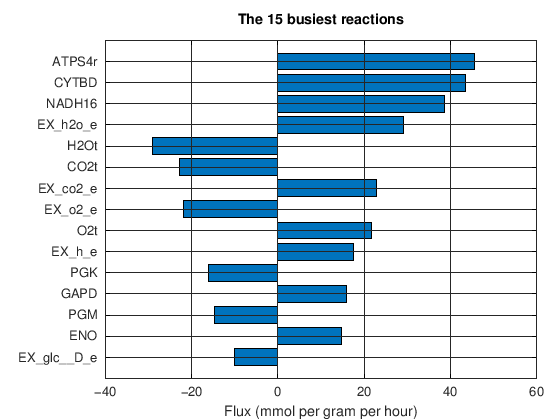

In [7]:
showFluxes(model, solution, 15)

**Question 2:** Look at the names in the list under the chart. Several of the busiest reactions have to do with ATP (`ATPS4r` = ATP synthase) and with breathing (`CYTBD` = cytochrome oxidase, `NADH16` = NADH dehydrogenase). Why do you think the cell spends so much effort on these?

✅ **Answer:** Building a new cell costs a lot of energy. These reactions form the **respiratory chain**, which uses oxygen to make most of the cell's ATP. ATP is the energy currency that powers almost every other reaction.

## Summary

* A **metabolic model** lists all reactions of a cell, with the genes behind them.
* **Flux balance analysis** finds the fluxes that let the cell grow fastest, without anything piling up and without eating more than allowed.
* From that, the computer predicts the **growth rate** and what the cell **takes up and releases**.

In the exercises you'll change the conditions and see how the bacterium reacts. Start with `02_exercise_oxygen.ipynb`.

## Sources

* **Model:** the *E. coli* core model (`e_coli_core`) from BiGG Models. Orth JD, Fleming RMT, Palsson BØ (2010). Reconstruction and use of microbial metabolic networks: the core *Escherichia coli* metabolic model as an educational guide. *EcoSal Plus* 4(1). [doi:10.1128/ecosalplus.10.2.1](https://doi.org/10.1128/ecosalplus.10.2.1)
* **Database:** King ZA et al. (2016). BiGG Models: A platform for integrating, standardizing and sharing genome-scale models. *Nucleic Acids Research* 44(D1):D515–D522. [doi:10.1093/nar/gkv1049](https://doi.org/10.1093/nar/gkv1049). BiGG Models © 2019 The Regents of the University of California; free for educational, research and non-profit use.
* **Software:** COBRA Toolbox v3.7.1. Heirendt L et al. (2019). Creation and analysis of biochemical constraint-based models using the COBRA Toolbox v.3.0. *Nature Protocols* 14:639–702. [doi:10.1038/s41596-018-0098-2](https://doi.org/10.1038/s41596-018-0098-2). It runs in [GNU Octave](https://octave.org) with the [GLPK](https://www.gnu.org/software/glpk/) solver.
* **Method:** Orth JD, Thiele I, Palsson BØ (2010). What is flux balance analysis? *Nature Biotechnology* 28:245–248. [doi:10.1038/nbt.1614](https://doi.org/10.1038/nbt.1614)